In [1]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())
df["TotalCharges"] = df["TotalCharges"].fillna(0)

df["Churned"] = (df["Churn"] == "Yes").astype(int)
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df["TenureGroup"] = pd.cut(df["tenure"], bins=[-1, 6, 12, 24, 48, 72],
                           labels=["0-6 mo", "7-12 mo", "13-24 mo", "25-48 mo", "49-72 mo"]).astype(str)
print("Cleaned:", df.shape)

Missing TotalCharges: 11
Cleaned: (7043, 23)


In [3]:
churn_rate = df["Churned"].mean()
lost_monthly = df.loc[df["Churned"] == 1, "MonthlyCharges"].sum()
total_monthly = df["MonthlyCharges"].sum()

print(f"Customers: {len(df):,}")
print(f"Churn rate: {churn_rate:.1%}")
print(f"Monthly revenue lost to churn: ${lost_monthly:,.0f} ({lost_monthly / total_monthly:.1%} of total)")

Customers: 7,043
Churn rate: 26.5%
Monthly revenue lost to churn: $139,131 (30.5% of total)


In [4]:
conn = sqlite3.connect(":memory:")
df.to_sql("customers", conn, index=False)

def q(sql):
    return pd.read_sql(sql, conn)

print("Churn by contract type")
display(q("""
    SELECT Contract, COUNT(*) AS customers,
           ROUND(AVG(Churned) * 100, 1) AS churn_pct,
           ROUND(SUM(CASE WHEN Churned = 1 THEN MonthlyCharges ELSE 0 END), 0) AS monthly_revenue_lost
    FROM customers GROUP BY Contract ORDER BY churn_pct DESC
"""))

print("Highest-risk segments")
display(q("""
    WITH segments AS (
        SELECT Contract, InternetService, TenureGroup,
               COUNT(*) AS customers,
               ROUND(AVG(Churned) * 100, 1) AS churn_pct,
               ROUND(SUM(CASE WHEN Churned = 1 THEN MonthlyCharges ELSE 0 END), 0) AS revenue_lost
        FROM customers
        GROUP BY Contract, InternetService, TenureGroup
        HAVING COUNT(*) >= 100
    )
    SELECT *, RANK() OVER (ORDER BY revenue_lost DESC) AS revenue_rank
    FROM segments ORDER BY revenue_lost DESC LIMIT 5
"""))

Churn by contract type


,Contract,customers,churn_pct,monthly_revenue_lost
0,Month-to-month,3875,42.7,120847.0
1,One year,1473,11.3,14118.0
2,Two year,1695,2.8,4165.0


Highest-risk segments


,Contract,InternetService,TenureGroup,customers,churn_pct,revenue_lost,revenue_rank
0,Month-to-month,Fiber optic,0-6 mo,619,74.2,37150.0,1
1,Month-to-month,Fiber optic,25-48 mo,521,43.4,20762.0,2
2,Month-to-month,Fiber optic,13-24 mo,425,50.6,19047.0,3
3,Month-to-month,Fiber optic,7-12 mo,297,62.0,16028.0,4
4,Month-to-month,DSL,0-6 mo,495,49.5,11000.0,5


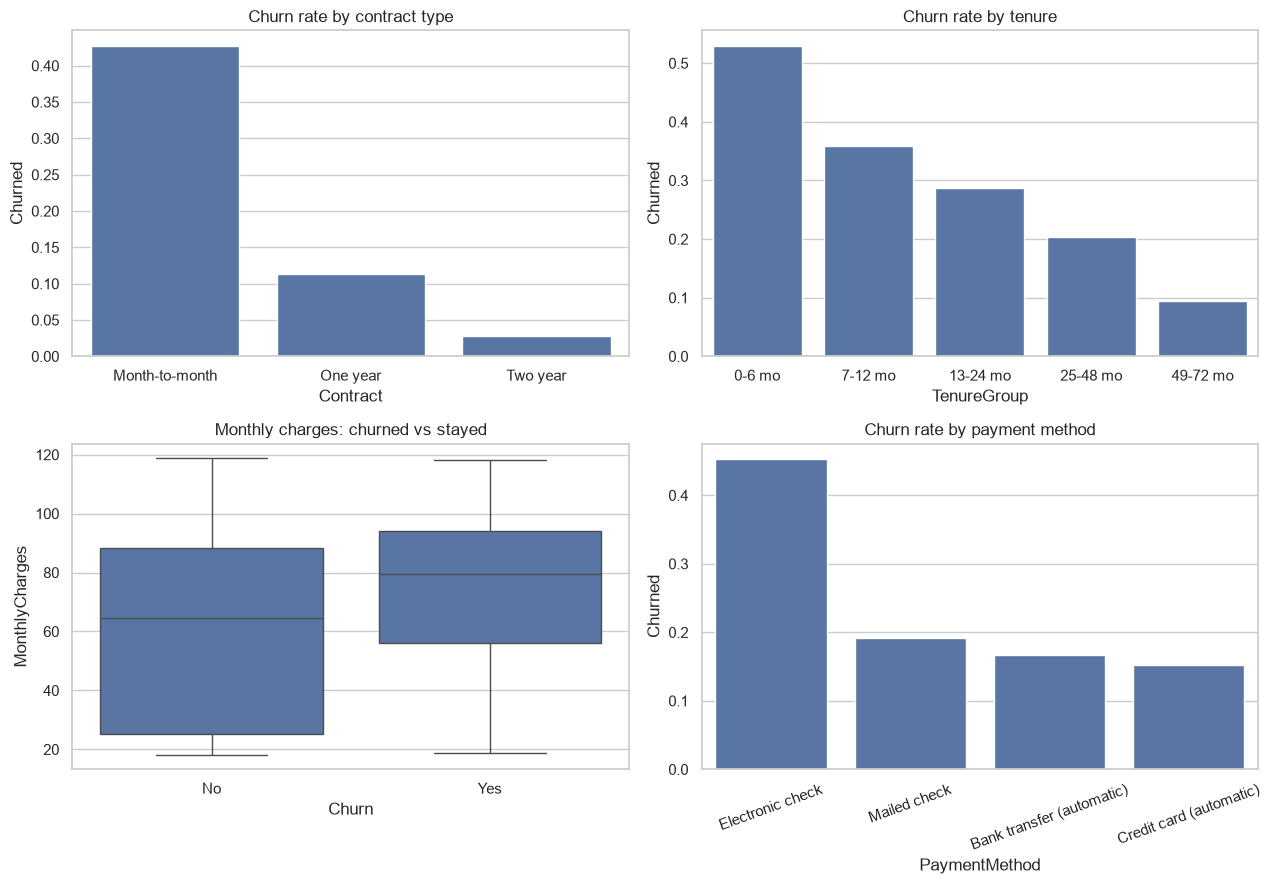

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.barplot(data=df, x="Contract", y="Churned", ax=axes[0, 0], errorbar=None)
axes[0, 0].set_title("Churn rate by contract type")
sns.barplot(data=df, x="TenureGroup", y="Churned", ax=axes[0, 1], errorbar=None,
            order=["0-6 mo", "7-12 mo", "13-24 mo", "25-48 mo", "49-72 mo"])
axes[0, 1].set_title("Churn rate by tenure")
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1, 0])
axes[1, 0].set_title("Monthly charges: churned vs stayed")
sns.barplot(data=df, x="PaymentMethod", y="Churned", ax=axes[1, 1], errorbar=None)
axes[1, 1].set_title("Churn rate by payment method")
axes[1, 1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig("churn_overview.png", dpi=150)
plt.show()

              precision    recall  f1-score   support

           0       0.91      0.74      0.81      1035
           1       0.52      0.80      0.63       374

    accuracy                           0.75      1409
   macro avg       0.72      0.77      0.72      1409
weighted avg       0.81      0.75      0.77      1409

ROC-AUC: 0.843


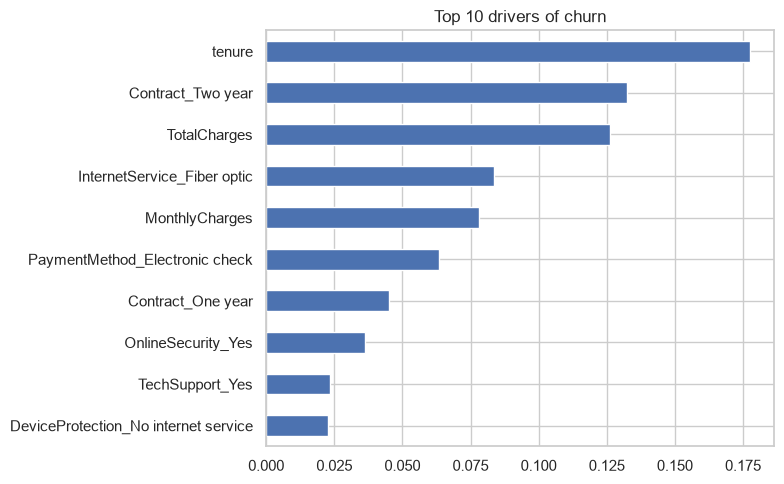

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

X = pd.get_dummies(df.drop(columns=["customerID", "Churn", "Churned", "TenureGroup"]), drop_first=True)
y = df["Churned"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = RandomForestClassifier(n_estimators=300, max_depth=8, class_weight="balanced", random_state=42)
model.fit(X_train, y_train)
print(classification_report(y_test, model.predict(X_test)))
print(f"ROC-AUC: {roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]):.3f}")

top = pd.Series(model.feature_importances_, index=X.columns).sort_values().tail(10)
top.plot(kind="barh", figsize=(8, 5), title="Top 10 drivers of churn")
plt.tight_layout()
plt.savefig("churn_drivers.png", dpi=150)
plt.show()

In [7]:
target = df[(df["Contract"] == "Month-to-month") & (df["tenure"] <= 12)]
at_risk = target.loc[target["Churned"] == 1, "MonthlyCharges"].sum()
print(f"Month-to-month customers in first year: {len(target):,}")
print(f"Their churn rate: {target['Churned'].mean():.1%} (vs {churn_rate:.1%} overall)")
print(f"Monthly revenue lost from this group: ${at_risk:,.0f}")
print(f"If retention saved 20% of them: ${at_risk * 0.2:,.0f}/month, ${at_risk * 0.2 * 12:,.0f}/year")

Month-to-month customers in first year: 1,994
Their churn rate: 51.4% (vs 26.5% overall)
Monthly revenue lost from this group: $68,301
If retention saved 20% of them: $13,660/month, $163,923/year
